# C04 — frozen project FZ301 on RAID + 54-source stage comparison

This notebook starts the C04 detector stage.

It preserves the already-frozen **FZ118 (118 coordinates)** and **project FZ186 v1 (118 + 68 POS coordinates)** definitions, then appends **115 explicitly frozen C04 coordinates** to obtain **301 total features**.

The added C04 block is:

- **72 named-entity coordinates:** 18 spaCy NER labels × {entity share, sentence mean, sentence population SD, sentence max}
- **10 identity-coreference proxy coordinates:** deterministic repeated noun-phrase chain summaries
- **16 entity-grid coordinates:** all S/O/X/- adjacent-sentence transition frequencies
- **15 Empath coordinates:** distribution/topicality summaries over the default Empath category scores
- **1 Yule-Q coherence coordinate**
- **1 topic-redundancy coordinate**

This is deliberately named `FZ301_project_v1`. It is **inspired by** Fröhling & Zubiaga's named-entity, coreference, entity-grid, Empath, and Yule-Q feature families; it is **not claimed to be a byte-for-byte reconstruction of their original implementation**. In particular, the obsolete `neuralcoref` dependency is replaced by a frozen identity-based noun-phrase proxy.

Training uses only the unchanged RAID training split and clones the same ExtraTrees estimator configuration used for the frozen FZ118/FZ186 stages. No fixed-54 text is added to training.

Evaluated AI stages:

1. **Original AI Text**
2. **FULL FZ118 — Post Step 4**
3. **FULL FZ186 — Post Step 8**

Outputs include stage AUROC/mean score, the detailed calibration-threshold TPR staircase for all three stages, and the top human-adjusted Post-Step-8 tree-path contribution gaps.

In [1]:
# %pip install empath

In [2]:
from pathlib import Path
import json, hashlib, pickle, re, math, warnings
from collections import Counter, defaultdict
from functools import lru_cache
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy, textstat, sklearn

from sklearn.base import clone
from sklearn.metrics import roc_curve, auc
from IPython.display import display

try:
    from empath import Empath
except ImportError as e:
    raise ImportError(
        "C04 needs the Python package `empath`. "
        "Run `%pip install empath` once in this Jupyter kernel, then rerun this cell."
    ) from e

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
BASE = ROOT / "results/causal/C02d2_fz118_ghostbuster_raid"
PRIOR = ROOT / "results/causal/C02e2_raid_feature_guided"
C03_RUN = ROOT / "results/causal/C03_fz186_raid_fixed54/cfa99a0382fb"
POST4_PATH = ROOT / "results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv"
LEX_ROOT = ROOT / "results/causal/C03e_lexical_micro_substitution"
FIG = ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED = 20260911
B = 2000
normalize = lambda t: str(t).replace("\n", " ").replace("\r", " ")

nlp = spacy.load("en_core_web_sm")
empath = Empath()

features = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus = pd.read_parquet(BASE / "paired_corpus.parquet")
assert features.source_id.is_unique and corpus.source_id.is_unique
text_map = corpus.set_index("source_id").text.to_dict()

raid = features.loc[features.dataset.eq("raid")].copy().reset_index(drop=True)
assert raid.source_id.is_unique
assert set(raid.source_id) <= set(text_map)

post4 = pd.read_csv(POST4_PATH, keep_default_na=False).sort_values("case_id").reset_index(drop=True)
assert len(post4) == 54 and post4.case_id.is_unique and post4.source_id.is_unique
assert post4.text.str.strip().ne("").all()

# Resolve the accepted Step-8 export without hard-coding a contract hash.
lex_files = sorted(LEX_ROOT.glob("*/texts_after_lexical_scored.csv"))
assert lex_files, f"No Step-8 export found under {LEX_ROOT}"

accepted_lex = []
for p in lex_files:
    try:
        d = pd.read_csv(p, keep_default_na=False).sort_values("case_id").reset_index(drop=True)
    except Exception:
        continue
    if (
        len(d) == 54
        and {"case_id", "source_id", "domain", "text"} <= set(d.columns)
        and d.case_id.is_unique
        and d.source_id.is_unique
        and d[["case_id", "source_id", "domain"]].equals(post4[["case_id", "source_id", "domain"]])
    ):
        # Prefer the known accepted endpoint when the score column is present.
        if "post_LEX_AI_score" not in d.columns or np.isclose(
            d["post_LEX_AI_score"].astype(float).mean(), 0.476988, atol=5e-6
        ):
            accepted_lex.append((p, d))

assert len(accepted_lex) == 1, (
    "Expected exactly one accepted Step-8 export. Candidates:\n"
    + "\n".join(str(p) for p, _ in accepted_lex)
)
POST8_PATH, post8 = accepted_lex[0]

original = post4[["case_id", "source_id", "domain"]].copy()
original["text"] = [normalize(text_map[s]) for s in original.source_id]
post4_stage = post4[["case_id", "source_id", "domain", "text"]].copy()
post8_stage = post8[["case_id", "source_id", "domain", "text"]].copy()

STAGES = {
    "Original AI Text": original,
    "FULL FZ118 — Post Step 4": post4_stage,
    "FULL FZ186 — Post Step 8": post8_stage,
}

for name, d in STAGES.items():
    assert len(d) == 54
    assert d[["case_id", "source_id", "domain"]].reset_index(drop=True).equals(
        post4[["case_id", "source_id", "domain"]].reset_index(drop=True)
    )

print("RAID rows:", len(raid))
print("Fixed AI cohort:", len(post4))
print("Accepted Step-8 file:", POST8_PATH.relative_to(ROOT))

RAID rows: 1818
Fixed AI cohort: 54
Accepted Step-8 file: results/causal/C03e_lexical_micro_substitution/60d5986e77d8/texts_after_lexical_scored.csv


In [3]:
# Exact frozen project FZ118 extractor copied forward from C03.

PUNCTUATION = [
    ("comma", ","), ("period", "."), ("colon", ":"), ("semicolon", ";"),
    ("question", "?"), ("exclamation", "!"), ("hyphen", "-"), ("quote", '"'),
    ("lparen", "("), ("rparen", ")"), ("lbracket", "["), ("rbracket", "]"),
    ("newline", "\n"),
]

google_words = [
    w.strip().lower()
    for w in (BASE / "google-10000-english.txt").read_text().splitlines()
    if w.strip()
]
GOOGLE_TOP = {n: set(google_words[:n]) for n in [100, 1000, 10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0

def clean_word_tokens(span):
    return [token.text.lower() for token in span if token.is_alpha]

def clean_pos_tokens(span):
    return [token.pos_ for token in span if token.is_alpha]

def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(tuple(sequence[i:i+n]) for i in range(len(sequence) - n + 1))

def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    return float(sum((a & b).values()) / denominator)

def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)
    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))

def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(multiset_overlap(words[:i], words[i+1:], n))
    return float(np.mean(values)) if values else 0.0

def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)

def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0

def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector

FEATURE_NAMES = json.loads((BASE / "fz118_feature_contract.json").read_text())["feature_names"]
assert len(FEATURE_NAMES) == 118

def fz118_frame(texts):
    arr = np.vstack([extract_fz118(t) for t in texts])
    return pd.DataFrame(arr, columns=FEATURE_NAMES)

# Sanity check against canonical stored original RAID vectors.
check_rows = original.iloc[:5]
stored = raid.set_index("source_id").loc[check_rows.source_id, FEATURE_NAMES].to_numpy(float)
recomputed = fz118_frame(check_rows.text.tolist()).to_numpy(float)
np.testing.assert_allclose(recomputed, stored, atol=1e-9, rtol=0)
print("✓ Exact FZ118 extractor sanity check passed.")

✓ Exact FZ118 extractor sanity check passed.


In [4]:
# Freeze the project FZ301 v1 feature contract: 186 inherited + 115 new = 301.

POS_TAGS = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM",
    "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X"
]
POS_STATS = ["token_share", "sentence_mean", "sentence_std", "sentence_max"]
POS_NAMES = [f"pos_{tag}_{stat}" for tag in POS_TAGS for stat in POS_STATS]
assert len(POS_NAMES) == 68

NER_LABELS = list(nlp.get_pipe("ner").labels)
assert len(NER_LABELS) == 18, (
    f"Expected the frozen en_core_web_sm 18-label NER inventory, got {NER_LABELS}"
)
NER_STATS = ["entity_share", "sentence_mean", "sentence_std", "sentence_max"]
NER_NAMES = [f"ner_{label}_{stat}" for label in NER_LABELS for stat in NER_STATS]
assert len(NER_NAMES) == 72

COREF_NAMES = [
    "coref_mentions_per_sentence",
    "coref_clusters_per_sentence",
    "coref_repeated_clusters_per_sentence",
    "coref_repeated_cluster_share",
    "coref_repeated_mention_share",
    "coref_cluster_size_mean",
    "coref_cluster_size_std",
    "coref_cluster_size_max",
    "coref_distinct_sentence_mean",
    "coref_cross_sentence_cluster_share",
]
assert len(COREF_NAMES) == 10

GRID_ROLES = ["S", "O", "X", "-"]
GRID_NAMES = [f"entity_grid_{a}_{b}" for a in GRID_ROLES for b in GRID_ROLES]
assert len(GRID_NAMES) == 16

EMPATH_NAMES = [
    "empath_all_mean", "empath_all_median", "empath_all_min",
    "empath_all_max", "empath_all_var",
    "empath_active_mean", "empath_active_median", "empath_active_min",
    "empath_active_max", "empath_active_var",
    "empath_q10", "empath_q25", "empath_q75", "empath_q90",
    "empath_active_share",
]
assert len(EMPATH_NAMES) == 15

Q_NAMES = ["yule_q_mean"]
TOPIC_NAMES = ["topic_redundancy_mean_cosine"]

NEW115_NAMES = NER_NAMES + COREF_NAMES + GRID_NAMES + EMPATH_NAMES + Q_NAMES + TOPIC_NAMES
assert len(NEW115_NAMES) == 115 and len(set(NEW115_NAMES)) == 115

F186 = FEATURE_NAMES + POS_NAMES
F301 = F186 + NEW115_NAMES
assert len(F301) == 301 and len(set(F301)) == 301

EMPATH_CATS = sorted(empath.cats.keys())
assert len(EMPATH_CATS) >= 190

def pos_vector(doc):
    tokens = [t for t in doc if not t.is_space]
    assert {t.pos_ for t in tokens} <= set(POS_TAGS), "Unexpected POS label"
    counts = Counter(t.pos_ for t in tokens)
    sentences = [
        Counter(t.pos_ for t in s if not t.is_space)
        for s in doc.sents
        if any(not t.is_space for t in s)
    ]
    out = []
    for tag in POS_TAGS:
        a = np.asarray([s[tag] for s in sentences], dtype=float)
        out.extend([
            counts[tag] / max(len(tokens), 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 68
    return out

def ner_vector(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    ents = list(doc.ents)
    total_ents = len(ents)
    overall = Counter(e.label_ for e in ents)

    sent_counts = []
    for sent in sentences:
        c = Counter(
            ent.label_
            for ent in ents
            if ent.start >= sent.start and ent.end <= sent.end
        )
        sent_counts.append(c)

    out = []
    for label in NER_LABELS:
        a = np.asarray([c[label] for c in sent_counts], dtype=float)
        out.extend([
            overall[label] / max(total_ents, 1),
            a.mean() if len(a) else 0.0,
            a.std(ddof=0) if len(a) else 0.0,
            a.max() if len(a) else 0.0,
        ])
    assert len(out) == 72
    return out

def noun_chunk_key(span):
    # Identity-based proxy: remove determiners/stop words where possible and lemmatize.
    content = [
        t.lemma_.lower()
        for t in span
        if t.is_alpha and not t.is_stop and t.pos_ not in {"DET"}
    ]
    if not content:
        content = [t.lemma_.lower() for t in span if t.is_alpha]
    return " ".join(content).strip()

def grammatical_role(span):
    dep = span.root.dep_.lower()
    if dep in {"nsubj", "nsubjpass", "csubj", "csubjpass"}:
        return "S"
    if dep in {"obj", "dobj", "iobj", "pobj", "dative", "attr", "oprd"}:
        return "O"
    return "X"

def identity_mentions(doc):
    sentences = [s for s in doc.sents if any(not t.is_space for t in s)]
    token_to_sent = {}
    for j, sent in enumerate(sentences):
        for t in sent:
            token_to_sent[t.i] = j

    mentions = []
    for chunk in doc.noun_chunks:
        key = noun_chunk_key(chunk)
        if not key:
            continue
        sent_idx = token_to_sent.get(chunk.root.i)
        if sent_idx is None:
            continue
        mentions.append((key, sent_idx, grammatical_role(chunk)))
    return sentences, mentions

def coref_proxy_vector(doc):
    sentences, mentions = identity_mentions(doc)
    clusters = defaultdict(list)
    for key, sent_idx, role in mentions:
        clusters[key].append((sent_idx, role))

    sizes = np.asarray([len(v) for v in clusters.values()], dtype=float)
    repeated = [v for v in clusters.values() if len(v) > 1]
    repeated_mentions = sum(len(v) for v in repeated)
    distinct_sentence_counts = np.asarray(
        [len({s for s, _ in v}) for v in clusters.values()],
        dtype=float,
    )
    cross_sentence = sum(len({s for s, _ in v}) > 1 for v in clusters.values())

    ns = max(len(sentences), 1)
    nc = len(clusters)
    nm = len(mentions)

    out = [
        nm / ns,
        nc / ns,
        len(repeated) / ns,
        safe_div(len(repeated), nc),
        safe_div(repeated_mentions, nm),
        sizes.mean() if len(sizes) else 0.0,
        sizes.std(ddof=0) if len(sizes) else 0.0,
        sizes.max() if len(sizes) else 0.0,
        distinct_sentence_counts.mean() if len(distinct_sentence_counts) else 0.0,
        safe_div(cross_sentence, nc),
    ]
    assert len(out) == 10
    return out

def entity_grid_vector(doc):
    sentences, mentions = identity_mentions(doc)
    n_sent = len(sentences)
    keys = sorted({k for k, _, _ in mentions})
    if n_sent < 2 or not keys:
        return [0.0] * 16

    # If an identity has multiple mentions in one sentence, keep the strongest role.
    precedence = {"S": 3, "O": 2, "X": 1}
    roles = {k: ["-"] * n_sent for k in keys}
    for key, sent_idx, role in mentions:
        old = roles[key][sent_idx]
        if old == "-" or precedence[role] > precedence.get(old, 0):
            roles[key][sent_idx] = role

    counts = Counter()
    for key in keys:
        row = roles[key]
        for a, b in zip(row[:-1], row[1:]):
            counts[(a, b)] += 1

    total = sum(counts.values())
    out = [safe_div(counts[(a, b)], total) for a in GRID_ROLES for b in GRID_ROLES]
    assert len(out) == 16
    return out

def empath_vector(text):
    scores = empath.analyze(str(text), categories=EMPATH_CATS, normalize=True)
    vals = np.asarray([float(scores[c]) for c in EMPATH_CATS], dtype=float)
    active = vals[vals > 0]

    all_stats = [
        vals.mean(), np.median(vals), vals.min(), vals.max(), vals.var(ddof=0)
    ] if len(vals) else [0.0] * 5
    active_stats = [
        active.mean(), np.median(active), active.min(), active.max(), active.var(ddof=0)
    ] if len(active) else [0.0] * 5

    quantiles = (
        np.quantile(vals, [0.10, 0.25, 0.75, 0.90]).tolist()
        if len(vals) else [0.0] * 4
    )
    out = all_stats + active_stats + quantiles + [safe_div(len(active), len(vals))]
    assert len(out) == 15
    return out

def content_sentence_sets(doc):
    out = []
    for sent in doc.sents:
        s = {
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        }
        if s:
            out.append(s)
    return out

def yule_q_mean(doc, max_terms=40):
    # Sentence-level Yule association over the most frequent content lemmas.
    sentence_sets = content_sentence_sets(doc)
    n = len(sentence_sets)
    if n < 2:
        return 0.0

    freq = Counter(w for s in sentence_sets for w in s)
    terms = [w for w, _ in sorted(freq.items(), key=lambda kv: (-kv[1], kv[0]))[:max_terms]]
    if len(terms) < 2:
        return 0.0

    present = {w: np.asarray([w in s for s in sentence_sets], dtype=bool) for w in terms}
    qs = []
    for i, a in enumerate(terms):
        A = present[a]
        for b in terms[i+1:]:
            B = present[b]
            n11 = int(np.sum(A & B))
            n10 = int(np.sum(A & ~B))
            n01 = int(np.sum(~A & B))
            n00 = int(np.sum(~A & ~B))
            den = n11 * n00 + n10 * n01
            if den:
                qs.append((n11 * n00 - n10 * n01) / den)
    return float(np.mean(qs)) if qs else 0.0

def topic_redundancy_mean_cosine(doc):
    # Pairwise cosine over sentence content-lemma count vectors.
    counters = []
    for sent in doc.sents:
        c = Counter(
            t.lemma_.lower()
            for t in sent
            if t.is_alpha and not t.is_stop and t.pos_ in {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}
        )
        if c:
            counters.append(c)

    if len(counters) < 2:
        return 0.0

    norms = [math.sqrt(sum(v * v for v in c.values())) for c in counters]
    sims = []
    for i, a in enumerate(counters):
        for j in range(i + 1, len(counters)):
            b = counters[j]
            dot = sum(v * b.get(k, 0) for k, v in a.items())
            denom = norms[i] * norms[j]
            sims.append(dot / denom if denom else 0.0)
    return float(np.mean(sims)) if sims else 0.0

def extension_vector(doc):
    out = (
        pos_vector(doc)
        + ner_vector(doc)
        + coref_proxy_vector(doc)
        + entity_grid_vector(doc)
        + empath_vector(doc.text)
        + [yule_q_mean(doc)]
        + [topic_redundancy_mean_cosine(doc)]
    )
    arr = np.asarray(out, dtype=np.float64)
    assert arr.shape == (183,)
    assert np.isfinite(arr).all()
    return arr

EXT_NAMES = POS_NAMES + NEW115_NAMES
assert len(EXT_NAMES) == 183

feature_manifest = {
    "name": "FZ301_project_v1",
    "source": (
        "Frozen project FZ186 v1 plus 115 C04 coordinates inspired by "
        "Fröhling & Zubiaga named-entity/coreference/entity-grid/Empath/Yule-Q families; "
        "not an exact original-paper reconstruction."
    ),
    "feature_names": F301,
    "blocks": {
        "FZ118": FEATURE_NAMES,
        "POS": POS_NAMES,
        "NER": NER_NAMES,
        "coreference_identity_proxy": COREF_NAMES,
        "entity_grid": GRID_NAMES,
        "Empath": EMPATH_NAMES,
        "Yule_Q": Q_NAMES,
        "topic_redundancy": TOPIC_NAMES,
    },
    "pos_tags": POS_TAGS,
    "pos_stats": POS_STATS,
    "ner_labels": NER_LABELS,
    "ner_stats": NER_STATS,
    "entity_grid_roles": GRID_ROLES,
    "coreference_policy": "identity-based normalized noun-chunk proxy; no neuralcoref",
    "empath_categories": EMPATH_CATS,
    "empath_policy": "default-category normalized scores summarized by 15 frozen statistics",
    "yule_q_policy": "mean sentence-level Yule Q over top-40 content lemmas by document frequency",
    "topic_redundancy_policy": "mean pairwise cosine of sentence content-lemma count vectors",
    "std_ddof": 0,
    "spacy": nlp.meta,
    "sklearn": sklearn.__version__,
    "empath_version": importlib_metadata.version("empath"),
}

manifest_hash = hashlib.sha256(
    json.dumps(feature_manifest, sort_keys=True, default=str).encode()
).hexdigest()[:12]

CACHE = ROOT / "results/causal/C04_fz301_feature_cache" / manifest_hash
CACHE.mkdir(parents=True, exist_ok=True)
(CACHE / "feature_manifest.json").write_text(json.dumps(feature_manifest, indent=2, default=str))

print("FZ301 manifest hash:", manifest_hash)
print("Feature counts:", {
    "FZ118": len(FEATURE_NAMES),
    "POS": len(POS_NAMES),
    "new_C04": len(NEW115_NAMES),
    "total": len(F301),
})

FZ301 manifest hash: 099d2763de75
Feature counts: {'FZ118': 118, 'POS': 68, 'new_C04': 115, 'total': 301}


In [5]:
# Build/cached RAID extensions, build the three fixed-54 stage matrices, and train FZ301.

def extension_frame(texts, desc="texts", batch_size=64):
    rows = []
    texts = list(map(str, texts))
    for i, doc in enumerate(nlp.pipe(texts, batch_size=batch_size)):
        rows.append(extension_vector(doc))
        if (i + 1) % 250 == 0 or i + 1 == len(texts):
            print(f"{desc}: {i+1}/{len(texts)}")
    return pd.DataFrame(np.vstack(rows), columns=EXT_NAMES)

RAID_CACHE = CACHE / "raid_extensions.parquet"
RAID_HASH = hashlib.sha256(
    "\n".join(f"{sid}\t{hashlib.sha256(normalize(text_map[sid]).encode()).hexdigest()}"
              for sid in raid.source_id).encode()
).hexdigest()

if RAID_CACHE.exists():
    cached = pd.read_parquet(RAID_CACHE)
    meta_path = CACHE / "raid_extensions_meta.json"
    meta = json.loads(meta_path.read_text())
    assert meta["raid_hash"] == RAID_HASH
    assert cached.source_id.tolist() == raid.source_id.tolist()
    XR_ext = cached[EXT_NAMES].copy()
    print("Loaded cached RAID FZ301 extensions:", RAID_CACHE.relative_to(ROOT))
else:
    raid_texts = [normalize(text_map[s]) for s in raid.source_id]
    XR_ext = extension_frame(raid_texts, desc="RAID")
    save = XR_ext.copy()
    save.insert(0, "source_id", raid.source_id.to_numpy())
    save.to_parquet(RAID_CACHE, index=False)
    (CACHE / "raid_extensions_meta.json").write_text(json.dumps({
        "raid_hash": RAID_HASH,
        "manifest_hash": manifest_hash,
        "n_rows": len(raid),
    }, indent=2))
    print("Saved RAID FZ301 extension cache:", RAID_CACHE.relative_to(ROOT))

XR = pd.concat(
    [raid[FEATURE_NAMES].reset_index(drop=True), XR_ext.reset_index(drop=True)],
    axis=1,
)
assert list(XR.columns) == F301
assert np.isfinite(XR.to_numpy(float)).all()

# Original AI stage: all 301 coordinates can reuse the exact RAID row because the text is unchanged.
raid_index = raid.set_index("source_id")
orig_indices = [raid_index.index.get_loc(s) for s in original.source_id]
X_original = XR.iloc[orig_indices].reset_index(drop=True)
assert original.source_id.tolist() == raid.iloc[orig_indices].source_id.tolist()

# Post-Step-4: reuse canonical saved FZ186 coordinates, calculate only the new C04 block.
c03_fixed = (
    pd.read_csv(C03_RUN / "fixed54_features.csv")
    .set_index("case_id")
    .loc[post4_stage.case_id]
    .reset_index()
)
assert list(c03_fixed.case_id) == list(post4_stage.case_id)
assert set(F186) <= set(c03_fixed.columns)

post4_ext = extension_frame(post4_stage.text.tolist(), desc="Post Step 4")
np.testing.assert_allclose(
    post4_ext[POS_NAMES].to_numpy(float),
    c03_fixed[POS_NAMES].to_numpy(float),
    atol=1e-9, rtol=0,
    err_msg="POS drift relative to canonical C03 FZ186 features",
)
X_post4 = pd.concat(
    [c03_fixed[F186].reset_index(drop=True), post4_ext[NEW115_NAMES].reset_index(drop=True)],
    axis=1,
)
assert list(X_post4.columns) == F301

# Post-Step-8: exact FZ118 re-extraction + frozen POS + new C04 block.
post8_118 = fz118_frame(post8_stage.text.tolist())
post8_ext = extension_frame(post8_stage.text.tolist(), desc="Post Step 8")
X_post8 = pd.concat([post8_118, post8_ext], axis=1)
assert list(X_post8.columns) == F301

STAGE_X = {
    "Original AI Text": X_original,
    "FULL FZ118 — Post Step 4": X_post4,
    "FULL FZ186 — Post Step 8": X_post8,
}
for name, X in STAGE_X.items():
    assert X.shape == (54, 301)
    assert np.isfinite(X.to_numpy(float)).all()

# Train only on the same unchanged RAID train split, cloning the frozen estimator family.
with (PRIOR / "fz118_raid_no_parentheses_detector.pkl").open("rb") as f:
    frozen_fz118_estimator = pickle.load(f)

train_mask = raid.split.eq("train").to_numpy()
assert set(post4.source_id).isdisjoint(set(raid.loc[train_mask, "source_id"]))

detector = clone(frozen_fz118_estimator)
detector.fit(XR.loc[train_mask, F301], raid.loc[train_mask, "label"].astype(int))
assert list(detector.feature_names_in_) == F301
assert list(detector.classes_) == [0, 1]

contract = {
    "feature_manifest_hash": manifest_hash,
    "training_rows": int(train_mask.sum()),
    "training_source_ids_sha256": hashlib.sha256(
        "\n".join(raid.loc[train_mask, "source_id"]).encode()
    ).hexdigest(),
    "post4_file_sha256": hashlib.sha256(POST4_PATH.read_bytes()).hexdigest(),
    "post8_file": str(POST8_PATH.relative_to(ROOT)),
    "post8_file_sha256": hashlib.sha256(POST8_PATH.read_bytes()).hexdigest(),
    "seed": SEED,
    "sklearn": sklearn.__version__,
}
run_id = hashlib.sha256(
    json.dumps(contract, sort_keys=True, default=str).encode()
).hexdigest()[:12]

OUT = ROOT / "results/causal/C04_fz301_raid_fixed54" / run_id
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "contract.json").write_text(json.dumps(contract, indent=2))
(OUT / "feature_manifest.json").write_text(json.dumps(feature_manifest, indent=2, default=str))
with (OUT / "FZ301.pkl").open("wb") as f:
    pickle.dump(detector, f)

raid.loc[train_mask, ["source_id", "domain", "label", "split"]].to_csv(
    OUT / "training_manifest.csv", index=False
)

for name, X in STAGE_X.items():
    stem = (
        name.lower()
        .replace("—", "")
        .replace(" ", "_")
        .replace("-", "_")
    )
    X.assign(case_id=post4.case_id.to_numpy()).to_csv(
        OUT / f"{stem}_features.csv", index=False
    )

print("✓ Trained frozen project FZ301 v1.")
print("Run:", OUT.relative_to(ROOT))
print("Training rows:", int(train_mask.sum()))

RAID: 250/1818
RAID: 500/1818
RAID: 750/1818
RAID: 1000/1818
RAID: 1250/1818
RAID: 1500/1818
RAID: 1750/1818
RAID: 1818/1818
Saved RAID FZ301 extension cache: results/causal/C04_fz301_feature_cache/099d2763de75/raid_extensions.parquet


/tmp/ipykernel_176269/1179652895.py:57: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()


Post Step 4: 54/54
Post Step 8: 54/54
✓ Trained frozen project FZ301 v1.
Run: results/causal/C04_fz301_raid_fixed54/d6c459f7c8a2
Training rows: 1272


/tmp/ipykernel_176269/1179652895.py:136: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X.assign(case_id=post4.case_id.to_numpy()).to_csv(


,stage,AUROC,mean_AI_score,median_AI_score
0,Original AI Text,0.875380,0.599424,0.596259
1,FULL FZ118 — Post Step 4,0.801146,0.544962,0.541416
2,FULL FZ186 — Post Step 8,0.699558,0.500605,0.478403


,requested_calibration_FPR,threshold,achieved_calibration_FPR,realized_test_FPR,Original AI Text,FULL FZ118 — Post Step 4,FULL FZ186 — Post Step 8
0,0.010,0.658918,0.007407,0.015988,0.370370,0.185185,0.129630
1,0.020,0.647070,0.014815,0.027846,0.407407,0.240741,0.166667
2,0.030,0.646190,0.023232,0.027846,0.407407,0.240741,0.166667
3,0.050,0.621228,0.046259,0.035898,0.407407,0.314815,0.259259
4,0.075,0.603792,0.071343,0.043949,0.481481,0.370370,0.259259
5,0.100,0.584567,0.096956,0.051151,0.537037,0.388889,0.296296
6,0.150,0.529959,0.145639,0.100320,0.685185,0.518519,0.333333
7,0.200,0.515532,0.196077,0.110608,0.685185,0.574074,0.407407
8,0.300,0.472016,0.296945,0.239344,0.759259,0.703704,0.518519
9,0.500,0.417566,0.499898,0.410386,0.870370,0.851852,0.722222


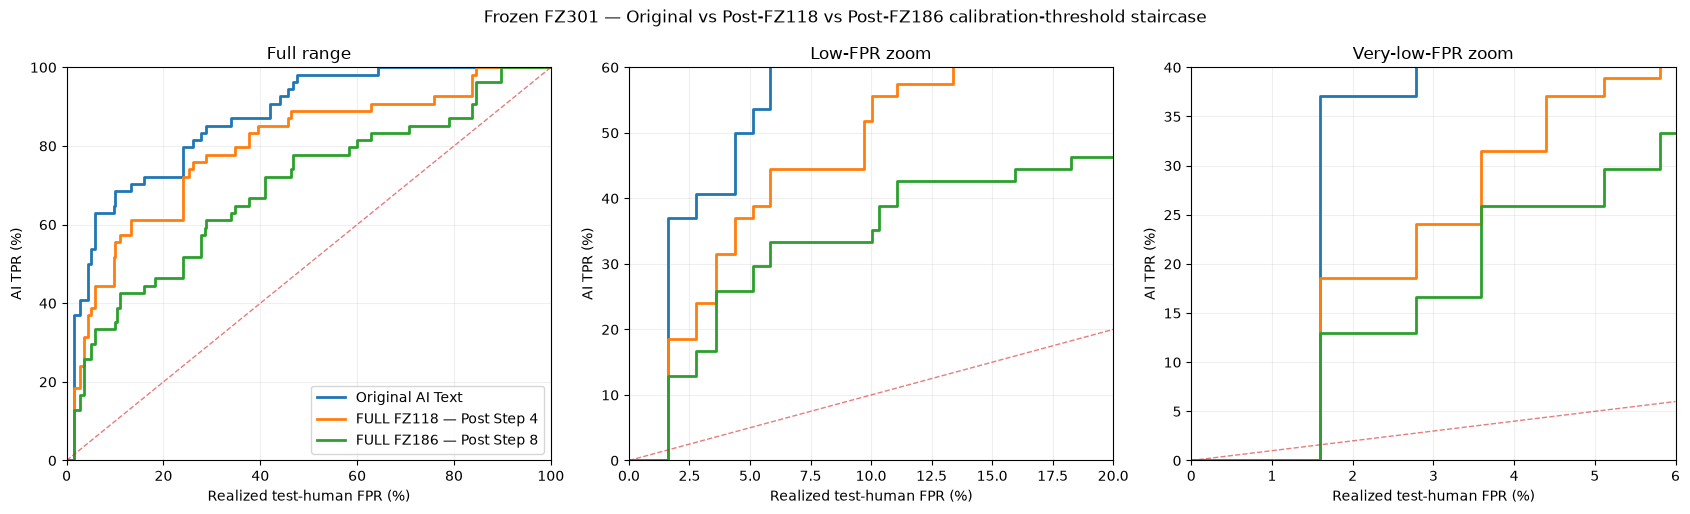

Saved staircase PDF/PNG to run dir and figures/.


In [6]:
# Evaluate Original vs Post-Step-4 vs Post-Step-8 and make the detailed TPR staircase.

mix = post4.domain.value_counts(normalize=True)

def human_mask(split):
    return (
        raid.split.eq(split)
        & raid.label.eq(0)
        & raid.domain.isin(mix.index)
    ).to_numpy()

calmask = human_mask("validation")
hmask = human_mask("test")

for mask in [calmask, hmask]:
    assert set(mix.index) <= set(raid.loc[mask, "domain"]), "Missing human genre"

def genre_weights(mask):
    g = raid.loc[mask, "domain"]
    counts = g.value_counts()
    w = np.asarray([mix[x] / counts[x] for x in g], dtype=float)
    assert np.isclose(w.sum(), 1.0)
    return w

wc = genre_weights(calmask)
wh = genre_weights(hmask)

cal_scores = detector.predict_proba(XR.loc[calmask, F301])[:, 1]
human_scores = detector.predict_proba(XR.loc[hmask, F301])[:, 1]
stage_scores = {
    name: detector.predict_proba(X[F301])[:, 1]
    for name, X in STAGE_X.items()
}

# Save human manifests exactly as in the previous detector stage.
for name, mask, w in [
    ("calibration", calmask, wc),
    ("test", hmask, wh),
]:
    raid.loc[mask, ["source_id", "domain"]].assign(weight=w).to_csv(
        OUT / f"human_{name}_manifest.csv", index=False
    )

summary = []
for name, scores in stage_scores.items():
    fpr, tpr, _ = roc_curve(
        np.r_[np.zeros(len(human_scores)), np.ones(54)],
        np.r_[human_scores, scores],
        sample_weight=np.r_[wh, np.ones(54) / 54],
        drop_intermediate=False,
    )
    summary.append({
        "stage": name,
        "AUROC": auc(fpr, tpr),
        "mean_AI_score": scores.mean(),
        "median_AI_score": np.median(scores),
    })

stage_summary = pd.DataFrame(summary)
stage_summary.to_csv(OUT / "stage_summary.csv", index=False)
display(stage_summary)

score_table = post4[["case_id", "source_id", "domain"]].copy()
for name, scores in stage_scores.items():
    score_table[name] = scores
score_table.to_csv(OUT / "stage_scores.csv", index=False)

# Full calibration-threshold sweep, strict score > threshold.
cuts = np.r_[np.inf, np.unique(cal_scores)[::-1], -np.inf]
cal_fpr = np.asarray([wc[cal_scores > cut].sum() for cut in cuts])
test_fpr = np.asarray([wh[human_scores > cut].sum() for cut in cuts])

stair = pd.DataFrame({
    "threshold": cuts,
    "calibration_FPR": cal_fpr,
    "test_FPR": test_fpr,
})
for name, scores in stage_scores.items():
    stair[name] = [(scores > cut).mean() for cut in cuts]

stair.to_csv(OUT / "detailed_TPR_staircase.csv", index=False)

# Requested operating-point table, using the largest calibration FPR not exceeding each budget.
budgets = [0.01, 0.02, 0.03, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30, 0.50]
ops = []
for budget in budgets:
    valid = np.flatnonzero(cal_fpr <= budget + 1e-12)
    j = valid[-1]
    row = {
        "requested_calibration_FPR": budget,
        "threshold": cuts[j],
        "achieved_calibration_FPR": cal_fpr[j],
        "realized_test_FPR": test_fpr[j],
    }
    for name in stage_scores:
        row[name] = stair.loc[j, name]
    ops.append(row)

operating_points = pd.DataFrame(ops)
operating_points.to_csv(OUT / "TPR_operating_points.csv", index=False)
display(operating_points)

# Same 3-panel staircase style used in the FZ186 wrap-up.
fig, axs = plt.subplots(1, 3, figsize=(17, 5.2))
panels = [
    ((0, 100), (0, 100), "Full range"),
    ((0, 20), (0, 60), "Low-FPR zoom"),
    ((0, 6), (0, 40), "Very-low-FPR zoom"),
]

for ax, (xlim, ylim, title) in zip(axs, panels):
    for name in stage_scores:
        ax.step(
            stair["test_FPR"] * 100,
            stair[name] * 100,
            where="post",
            label=name,
            linewidth=2,
        )
    lo = max(xlim[0], ylim[0])
    hi = min(xlim[1], ylim[1])
    ax.plot([lo, hi], [lo, hi], linestyle="--", linewidth=1, alpha=0.6)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel("Realized test-human FPR (%)")
    ax.set_ylabel("AI TPR (%)")
    ax.set_title(title)
    ax.grid(alpha=0.2)

axs[0].legend(loc="lower right")
fig.suptitle("Frozen FZ301 — Original vs Post-FZ118 vs Post-FZ186 calibration-threshold staircase")
fig.tight_layout()

for folder in [OUT, FIG]:
    fig.savefig(folder / "C04_FZ301_original_postFZ118_postFZ186_TPR_staircase.pdf", bbox_inches="tight")
    fig.savefig(folder / "C04_FZ301_original_postFZ118_postFZ186_TPR_staircase.png", dpi=220, bbox_inches="tight")
plt.show()

print("Saved staircase PDF/PNG to run dir and figures/.")

,feature,raw_mean_contribution,human_adjusted_gap,ci_low,ci_high,fraction_AI_directed,feature_family
0,ner_ORG_sentence_std,0.000990,0.002801,0.001124,0.004641,0.611111,Named entity
1,ner_ORG_sentence_mean,0.001025,0.002614,0.000993,0.004357,0.648148,Named entity
2,ner_CARDINAL_sentence_max,0.000863,0.002307,0.001029,0.003535,0.648148,Named entity
3,ner_ORG_sentence_max,0.000880,0.002142,0.000619,0.003668,0.592593,Named entity
4,share_unique_words,-0.000738,0.002104,0.000283,0.004097,0.462963,Inherited FZ118
5,pos_ADV_sentence_max,0.001306,0.002016,0.000882,0.003210,0.611111,POS
6,ner_PERSON_sentence_mean,0.000896,0.001980,0.001109,0.002753,0.722222,Named entity
7,ner_CARDINAL_sentence_std,0.000426,0.001798,0.000656,0.002896,0.629630,Named entity
8,ner_WORK_OF_ART_entity_share,0.000109,0.001699,0.000526,0.003169,0.462963,Named entity
9,share_google_top10000,0.000370,0.001659,0.000172,0.003179,0.611111,Inherited FZ118


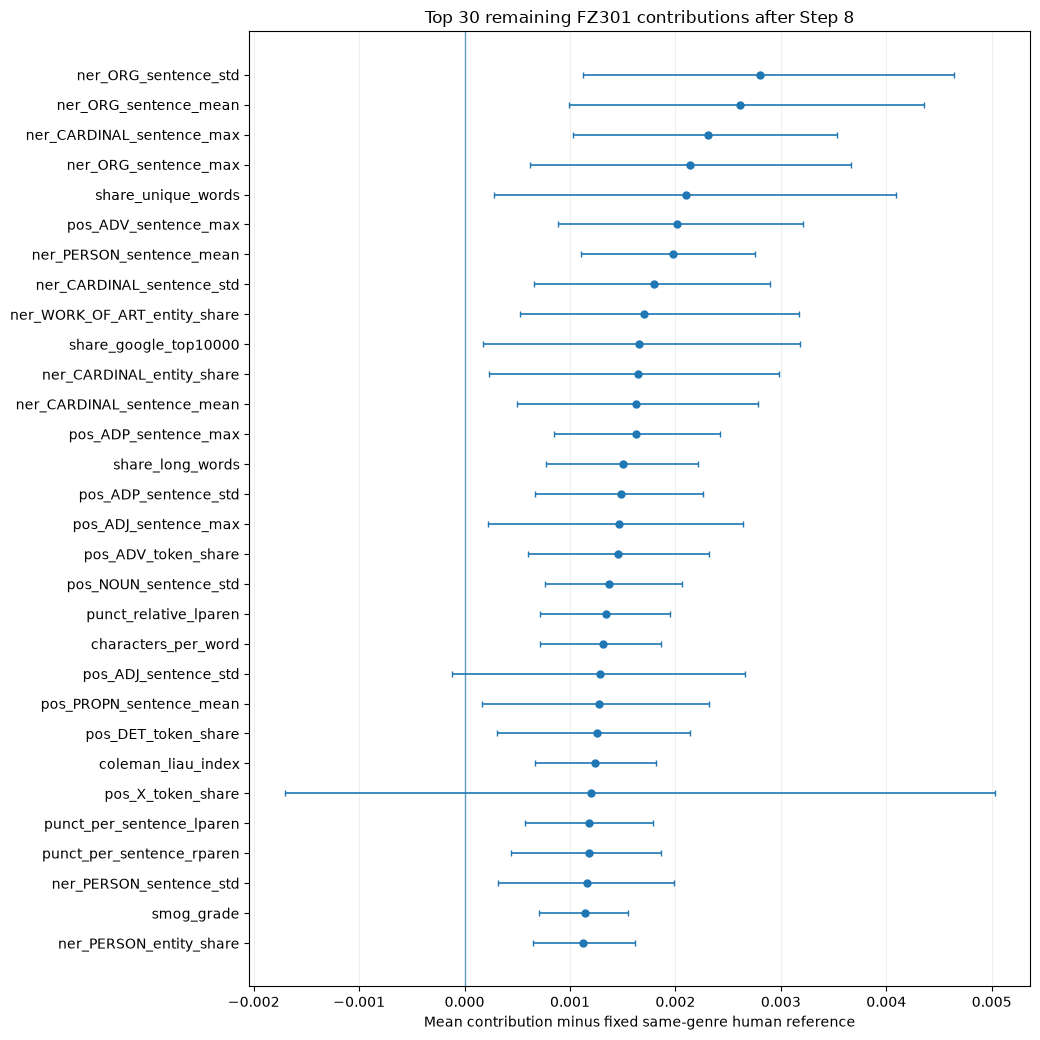

Contribution bias: 0.5000000000000048
Saved contribution PDF/PNG to run dir and figures/.


In [7]:
# Exact tree-path contribution decomposition for Post-Step-8, human-adjusted by fixed same-genre test-human reference.

def forest_contributions(model, frame):
    X = np.asarray(frame, dtype=np.float32)
    output = np.zeros_like(X, dtype=float)
    bias = 0.0

    for estimator in model.estimators_:
        tree = estimator.tree_
        value = tree.value[:, 0, :].astype(float)
        prob = value[:, 1] / value.sum(axis=1)
        bias += prob[0] / len(model.estimators_)

        for i, row in enumerate(X):
            node = 0
            while tree.children_left[node] != tree.children_right[node]:
                feature = tree.feature[node]
                child = (
                    tree.children_left[node]
                    if row[feature] <= tree.threshold[node]
                    else tree.children_right[node]
                )
                output[i, feature] += (
                    prob[child] - prob[node]
                ) / len(model.estimators_)
                node = child

    pred = model.predict_proba(frame)[:, 1]
    np.testing.assert_allclose(bias + output.sum(axis=1), pred, atol=1e-8, rtol=0)
    return output, bias

post8_contrib, contribution_bias = forest_contributions(detector, X_post8[F301])
human_contrib, _ = forest_contributions(detector, XR.loc[hmask, F301])

human_ref = (
    pd.DataFrame(human_contrib, columns=F301)
    .assign(domain=raid.loc[hmask, "domain"].to_numpy())
    .groupby("domain")[F301]
    .mean()
)

gap = post8_contrib - human_ref.loc[post8_stage.domain].to_numpy()

# Genre-stratified bootstrap over the fixed 54 AI cases, same project convention as C03.
rng = np.random.default_rng(SEED)
boot = np.zeros((B, len(F301)), dtype=float)
for domain in sorted(mix.index):
    ix = np.flatnonzero(post8_stage.domain.to_numpy() == domain)
    draw = rng.choice(ix, size=(B, len(ix)), replace=True)
    boot += (len(ix) / 54.0) * gap[draw].mean(axis=1)

lo, hi = np.quantile(boot, [0.025, 0.975], axis=0)

def feature_block(name):
    if name in FEATURE_NAMES:
        return "Inherited FZ118"
    if name in POS_NAMES:
        return "POS"
    if name in NER_NAMES:
        return "Named entity"
    if name in COREF_NAMES:
        return "Coreference proxy"
    if name in GRID_NAMES:
        return "Entity grid"
    if name in EMPATH_NAMES:
        return "Empath"
    if name in Q_NAMES:
        return "Yule Q"
    if name in TOPIC_NAMES:
        return "Topic redundancy"
    raise KeyError(name)

contribution_ranking = pd.DataFrame({
    "feature": F301,
    "raw_mean_contribution": post8_contrib.mean(axis=0),
    "human_adjusted_gap": gap.mean(axis=0),
    "ci_low": lo,
    "ci_high": hi,
    "fraction_AI_directed": (gap > 0).mean(axis=0),
})
contribution_ranking["feature_family"] = contribution_ranking.feature.map(feature_block)
contribution_ranking = contribution_ranking.sort_values(
    "human_adjusted_gap", ascending=False
).reset_index(drop=True)

contribution_ranking.to_csv(OUT / "post_step8_remaining_contributions.csv", index=False)

pd.DataFrame(post8_contrib, columns=F301).assign(
    case_id=post8_stage.case_id.to_numpy()
).to_csv(OUT / "post_step8_case_contributions.csv", index=False)

pd.DataFrame(gap, columns=F301).assign(
    case_id=post8_stage.case_id.to_numpy()
).to_csv(OUT / "post_step8_case_contribution_gaps.csv", index=False)

display(contribution_ranking.head(30))

# Top 30 positive remaining AI-directed gaps.
top = contribution_ranking.head(30).iloc[::-1].reset_index(drop=True)
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(10.5, 10.5))
x = top["human_adjusted_gap"].to_numpy()
xerr = np.vstack([
    x - top["ci_low"].to_numpy(),
    top["ci_high"].to_numpy() - x,
])

ax.errorbar(
    x, y, xerr=xerr,
    fmt="o", capsize=2, linewidth=1.2, markersize=5
)
ax.axvline(0, linewidth=1, alpha=0.7)
ax.set_yticks(y)
ax.set_yticklabels(top["feature"])
ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_title("Top 30 remaining FZ301 contributions after Step 8")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()

for folder in [OUT, FIG]:
    fig.savefig(folder / "C04_FZ301_postStep8_top_contributions.pdf", bbox_inches="tight")
    fig.savefig(folder / "C04_FZ301_postStep8_top_contributions.png", dpi=220, bbox_inches="tight")
plt.show()

print("Contribution bias:", contribution_bias)
print("Saved contribution PDF/PNG to run dir and figures/.")

In [8]:
# C04a — audit the dominant FZ301 ORG named-entity signal.
#
# Compare final Step-8 AI against the same fixed genre-matched
# human test reference used for contribution analysis.

ORG_FEATURES = [
    "ner_ORG_entity_share",
    "ner_ORG_sentence_mean",
    "ner_ORG_sentence_std",
    "ner_ORG_sentence_max",
]

assert set(ORG_FEATURES) <= set(F301)

# ------------------------------------------------------------
# Raw feature comparison.
# ------------------------------------------------------------

ai_org = X_post8[ORG_FEATURES].copy()
ai_org.insert(0, "domain", post8_stage["domain"].to_numpy())
ai_org.insert(0, "case_id", post8_stage["case_id"].to_numpy())

human_org = XR.loc[hmask, ORG_FEATURES].copy()
human_org.insert(
    0,
    "domain",
    raid.loc[hmask, "domain"].to_numpy(),
)

human_genre = (
    human_org
    .groupby("domain")[ORG_FEATURES]
    .agg(
        ["mean", "median", "std"]
    )
)

display(human_genre)

print("\nOverall Step-8 AI:")
display(
    ai_org[ORG_FEATURES]
    .agg(
        ["mean", "median", "std", "min", "max"]
    )
)

print("\nOverall fixed test-human:")
display(
    human_org[ORG_FEATURES]
    .agg(
        ["mean", "median", "std", "min", "max"]
    )
)


# ------------------------------------------------------------
# Per-case comparison against SAME-GENRE human medians.
# ------------------------------------------------------------

human_medians = (
    human_org
    .groupby("domain")[ORG_FEATURES]
    .median()
)

audit = ai_org.copy()

for f in ORG_FEATURES:
    audit[f"{f}_human_median"] = [
        human_medians.loc[d, f]
        for d in audit["domain"]
    ]

    audit[f"{f}_delta"] = (
        audit[f]
        - audit[f"{f}_human_median"]
    )


print("\nFraction of 54 above same-genre human median:")

for f in ORG_FEATURES:
    x = audit[f"{f}_delta"]

    print(
        f"{f:28s}",
        f"{(x > 0).sum():2d}/54",
        f"mean delta={x.mean():+.6f}",
    )


# ------------------------------------------------------------
# Directly inspect the actual ORG mentions and sentence layout.
# ------------------------------------------------------------

def org_sentence_audit(text):

    doc = nlp(str(text))

    rows = []

    for sent_i, sent in enumerate(doc.sents):

        orgs = [
            ent.text
            for ent in doc.ents
            if ent.label_ == "ORG"
            and ent.start >= sent.start
            and ent.end <= sent.end
        ]

        if orgs:
            rows.append({
                "sentence_index":
                    sent_i,

                "n_ORG":
                    len(orgs),

                "ORG_mentions":
                    " | ".join(orgs),

                "sentence":
                    sent.text.strip(),
            })

    return rows


# Rank cases by the three dominant ORG coordinates jointly.
rank_cols = [
    "ner_ORG_sentence_std_delta",
    "ner_ORG_sentence_mean_delta",
    "ner_ORG_sentence_max_delta",
]

audit["ORG_excess_score"] = (
    audit[rank_cols]
    .clip(lower=0)
    .sum(axis=1)
)

audit = audit.sort_values(
    "ORG_excess_score",
    ascending=False,
).reset_index(drop=True)

display(
    audit[
        [
            "case_id",
            "domain",
            "ORG_excess_score",
            *ORG_FEATURES,
            *[
                f"{x}_delta"
                for x in ORG_FEATURES
            ],
        ]
    ].head(20)
)


# ------------------------------------------------------------
# Print ORG-bearing sentences for the worst 15 cases.
# ------------------------------------------------------------

text_by_case = (
    post8_stage
    .set_index("case_id")["text"]
)

for row in audit.head(15).itertuples():

    print("\n" + "=" * 100)
    print(
        row.case_id,
        "|",
        row.domain,
        "| excess =",
        f"{row.ORG_excess_score:.6f}",
    )

    found = org_sentence_audit(
        text_by_case.loc[row.case_id]
    )

    if not found:
        print("NO ORG ENTITIES FOUND")
        continue

    for x in found:
        print(
            f"\n[{x['sentence_index']}] "
            f"ORG x{x['n_ORG']}: "
            f"{x['ORG_mentions']}"
        )
        print(x["sentence"])


audit.to_csv(
    OUT / "C04a_ORG_audit.csv",
    index=False,
)

print(
    "\nSaved:",
    OUT / "C04a_ORG_audit.csv",
)

ner_ORG_entity_share                     ner_ORG_sentence_mean  \
                          mean    median       std                  mean   
domain                                                                     
abstracts             0.469426  0.400000  0.361855              0.423584   
books                 0.167897  0.175192  0.137931              0.354964   
news                  0.191208  0.176471  0.119579              0.397596   
recipes               0.055623  0.038462  0.061195              0.079535   
reddit                0.201190  0.000000  0.356380              0.060293   
reviews               0.157029  0.162500  0.148114              0.211803   
wiki                  0.225969  0.192308  0.114013              0.775769   

                              ner_ORG_sentence_std                      \
             median       std                 mean    median       std   
domain                                                                   
abstracts  0.250000  0.433664             0.512530  0.433013  0.390085   
books      0.436508  0.283733             0.448070  0.476565  0.304358   
news       0.277778  0.292046             0.577226  0.489898  0.277957   
recipes    0.052632  0.089912             0.267930  0.223297  0.281818   
reddit     0.000000  0.116471             0.114991  0.000000  0.181010   
reviews    0.170040  0.218804             0.322714  0.353408  0.290904   
wiki       0.727273  0.379389             0.848113  0.799305  0.327789   

          ner_ORG_sentence_max                   
                          mean median       std  
domain                                           
abstracts             1.478261    1.0  1.201119  
books                 1.222222    1.0  0.878204  
news                  1.760000    1.0  0.969536  
recipes               1.047619    1.0  1.071270  
reddit                0.312500    0.0  0.478714  
reviews               0.833333    1.0  0.752773  
wiki                  2.473684    2.0  1.073334


Overall Step-8 AI:


,ner_ORG_entity_share,ner_ORG_sentence_mean,ner_ORG_sentence_std,ner_ORG_sentence_max
mean,0.183289,0.273922,0.380304,1.129630
median,0.127717,0.177866,0.400000,1.000000
std,0.221252,0.336215,0.338028,1.064811
min,0.000000,0.000000,0.000000,0.000000
max,0.833333,1.666667,1.374369,4.000000



Overall fixed test-human:


,ner_ORG_entity_share,ner_ORG_sentence_mean,ner_ORG_sentence_std,ner_ORG_sentence_max
mean,0.220483,0.349352,0.467195,1.398438
median,0.166667,0.200000,0.405163,1.000000
std,0.250495,0.369804,0.368771,1.145617
min,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.857143,1.581139,5.000000



Fraction of 54 above same-genre human median:
ner_ORG_entity_share         25/54 mean delta=+0.005818
ner_ORG_sentence_mean        21/54 mean delta=-0.023820
ner_ORG_sentence_std         20/54 mean delta=-0.047505
ner_ORG_sentence_max         15/54 mean delta=+0.074074


,case_id,domain,ORG_excess_score,ner_ORG_entity_share,ner_ORG_sentence_mean,ner_ORG_sentence_std,ner_ORG_sentence_max,ner_ORG_entity_share_delta,ner_ORG_sentence_mean_delta,ner_ORG_sentence_std_delta,ner_ORG_sentence_max_delta
0,gate_0079,abstracts,5.358023,0.833333,1.666667,1.374369,4.0,0.433333,1.416667,0.941356,3.0
1,gate_0049,recipes,3.910424,0.153846,0.272727,0.913625,4.0,0.115385,0.220096,0.690328,3.0
2,gate_0095,news,2.457919,0.333333,0.437500,0.788095,3.0,0.156863,0.159722,0.298197,2.0
3,gate_0090,abstracts,1.616847,0.800000,0.571429,0.728431,2.0,0.400000,0.321429,0.295419,1.0
4,gate_0028,abstracts,1.580750,0.500000,0.500000,0.763763,2.0,0.100000,0.250000,0.330750,1.0
5,gate_0022,abstracts,1.580750,0.750000,0.500000,0.763763,2.0,0.350000,0.250000,0.330750,1.0
6,gate_0066,news,1.553295,0.277778,0.625000,0.695971,2.0,0.101307,0.347222,0.206073,1.0
7,gate_0005,reddit,1.492784,0.500000,0.142857,0.349927,1.0,0.500000,0.142857,0.349927,1.0
8,gate_0085,recipes,1.480849,0.090909,0.181818,0.574960,2.0,0.052448,0.129187,0.351663,1.0
9,gate_0078,wiki,1.464285,0.400000,1.090909,0.899954,3.0,0.207692,0.363636,0.100649,1.0



gate_0079 | abstracts | excess = 5.358023

[1] ORG x1: 3D
Unlike 2D images, 3D medical images offer more detailed structures and robust segmentation capabilities.

[2] ORG x1: 3D
However, effectively utilizing the rich information in 3D medical images is still challenge.

[3] ORG x3: UXNet | 3D | UXNet
This paper introduces UXNet, a novel deep learning architecture for 3D medical image segmentation; UXNet employs a unique upsampled encoder-decoder network with a multi level feature aggregation mechanism.

[4] ORG x4: UXNet | LLC | SYNAPSE BREAST CT | UXNet
This mechanism enhances the spatial information by upsampling low level features and captures complex structures by aggregating multi level features; UXNet learns more robust representations, improving segmentation accuracy; Extensive experiments on three benchmark datasets including ISLES2017, LLC and SYNAPSE BREAST CT, show that UXNet outperforms state-of-the-art methods.

[5] ORG x1: https //github.com/CCF-Union/UXNet
The source 

,feature,human_relative_band,n,mean_raw_value,mean_contribution_gap,median_contribution_gap,fraction_AI_directed
0,ner_ORG_entity_share,<q10,6,0.018078,0.004127,0.003328,1.000000
1,ner_ORG_entity_share,q10-q25,12,0.018673,0.004121,0.004283,1.000000
2,ner_ORG_entity_share,q25-q75,20,0.178128,-0.000528,-0.000341,0.300000
3,ner_ORG_entity_share,q75-q90,12,0.391942,-0.001708,-0.001626,0.250000
4,ner_ORG_entity_share,>q90,4,0.324797,-0.002687,-0.002477,0.000000
5,ner_ORG_sentence_mean,<q10,6,0.051852,0.012022,0.010606,1.000000
6,ner_ORG_sentence_mean,q10-q25,13,0.094406,0.008352,0.009042,1.000000
7,ner_ORG_sentence_mean,q25-q75,24,0.277023,0.000170,0.000713,0.583333
8,ner_ORG_sentence_mean,q75-q90,7,0.615678,-0.004140,-0.003616,0.142857
9,ner_ORG_sentence_mean,>q90,4,0.573781,-0.003658,-0.000896,0.250000


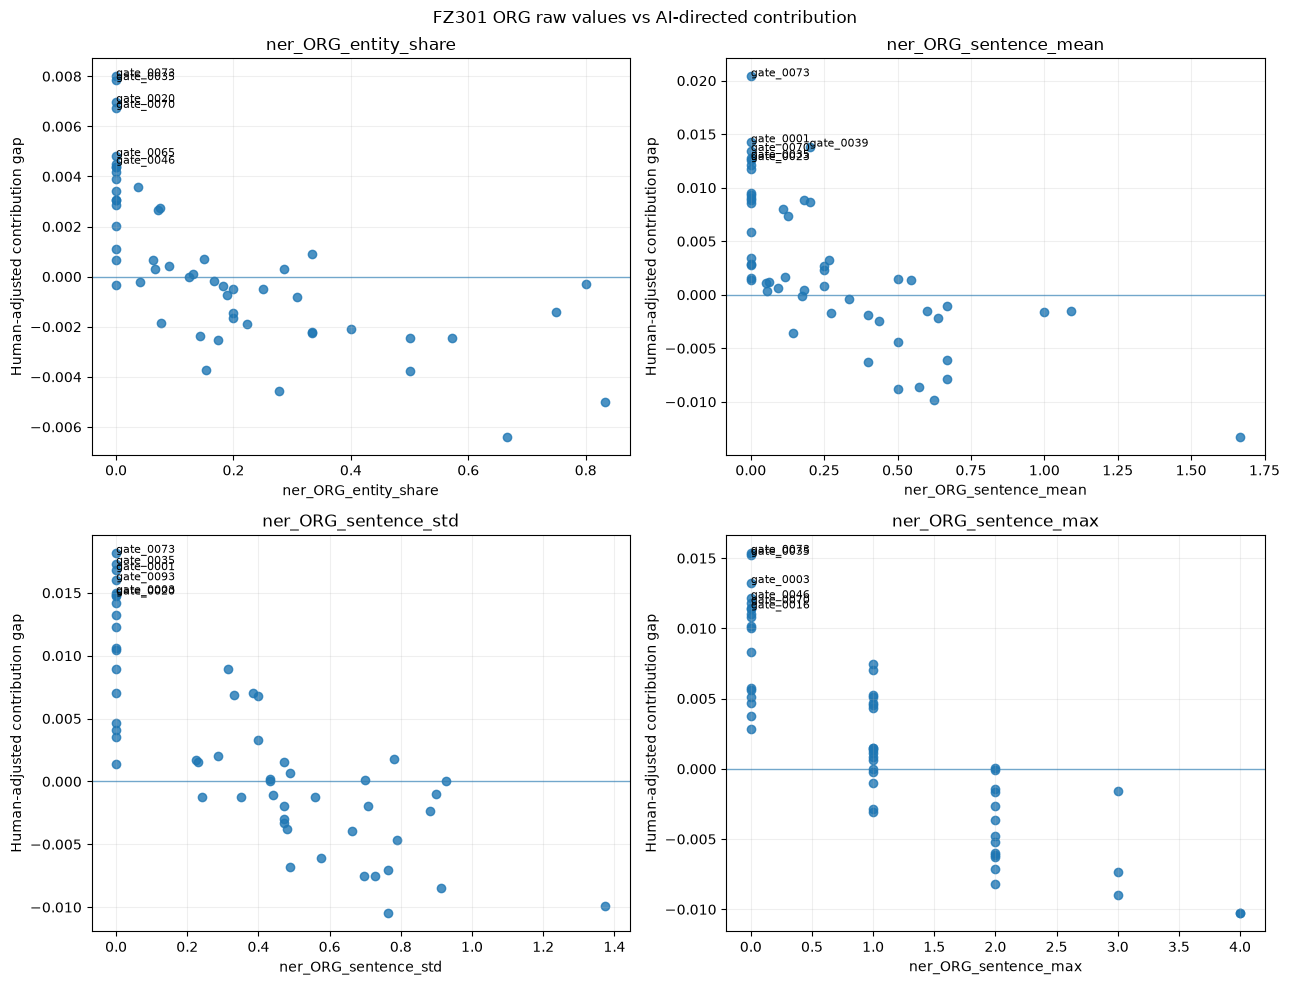


Top cases by total ORG contribution gap:


,case_id,domain,ORG_total_gap,ORG_positive_gap,ner_ORG_entity_share,ner_ORG_sentence_mean,ner_ORG_sentence_std,ner_ORG_sentence_max,ner_ORG_entity_share_contribution_gap,ner_ORG_sentence_mean_contribution_gap,ner_ORG_sentence_std_contribution_gap,ner_ORG_sentence_max_contribution_gap
37,gate_0073,wiki,0.061959,0.061959,0.000000,0.000000,0.000000,0.0,0.007996,0.020404,0.018181,0.015379
20,gate_0035,books,0.053170,0.053170,0.000000,0.000000,0.000000,0.0,0.007844,0.012780,0.017308,0.015238
0,gate_0001,abstracts,0.046795,0.046795,0.000000,0.000000,0.000000,0.0,0.004385,0.014243,0.016806,0.011361
36,gate_0070,books,0.046696,0.046696,0.000000,0.000000,0.000000,0.0,0.006737,0.013429,0.014745,0.011785
51,gate_0093,news,0.042176,0.042176,0.000000,0.000000,0.000000,0.0,0.004372,0.011749,0.015999,0.010057
13,gate_0023,books,0.041150,0.041150,0.000000,0.000000,0.000000,0.0,0.004181,0.012576,0.014213,0.010179
6,gate_0016,books,0.040756,0.040756,0.000000,0.000000,0.000000,0.0,0.003916,0.012157,0.013263,0.011419
1,gate_0003,news,0.039874,0.039874,0.000000,0.000000,0.000000,0.0,0.003056,0.008619,0.014972,0.013227
10,gate_0020,reviews,0.039457,0.039457,0.000000,0.000000,0.000000,0.0,0.006970,0.009335,0.014865,0.008287
24,gate_0046,abstracts,0.037945,0.037945,0.000000,0.000000,0.000000,0.0,0.004506,0.009042,0.012246,0.012153



ORG contribution by domain:


,n,mean_ORG_total_gap,mean_ORG_positive_gap
domain,,,
reviews,1,0.039457,0.039457
books,7,0.031841,0.033149
news,12,0.011662,0.017196
reddit,6,0.007076,0.010151
wiki,9,0.006989,0.011066
recipes,9,-0.002860,0.004277
abstracts,10,-0.004140,0.009212


In [9]:
# C04a — ORG contribution-direction audit
#
# Determine exactly WHICH ORG values are producing AI-directed
# FZ301 contribution after Step 8.
#
# Uses the already-computed:
#   post8_contrib
#   human_contrib
#   human_ref
#   gap
#   X_post8
#   post8_stage
#   F301

ORG_FEATURES = [
    "ner_ORG_entity_share",
    "ner_ORG_sentence_mean",
    "ner_ORG_sentence_std",
    "ner_ORG_sentence_max",
]

org_idx = {
    f: F301.index(f)
    for f in ORG_FEATURES
}


# ------------------------------------------------------------
# Per-case HUMAN-ADJUSTED tree-path gap for each ORG feature.
# ------------------------------------------------------------

org_cases = (
    post8_stage[
        ["case_id", "domain"]
    ]
    .copy()
    .reset_index(drop=True)
)

for f in ORG_FEATURES:

    j = org_idx[f]

    org_cases[f] = (
        X_post8[f]
        .to_numpy(float)
    )

    org_cases[
        f"{f}_contribution_gap"
    ] = (
        gap[:, j]
    )


# ------------------------------------------------------------
# Same-genre human quantiles.
# ------------------------------------------------------------

human_org_raw = (
    XR.loc[
        hmask,
        ORG_FEATURES
    ]
    .copy()
)

human_org_raw[
    "domain"
] = (
    raid.loc[
        hmask,
        "domain"
    ]
    .to_numpy()
)

quantiles = {}

for f in ORG_FEATURES:

    q = (
        human_org_raw
        .groupby("domain")[f]
        .quantile(
            [
                0.10,
                0.25,
                0.50,
                0.75,
                0.90,
            ]
        )
        .unstack()
    )

    q.columns = [
        "q10",
        "q25",
        "q50",
        "q75",
        "q90",
    ]

    quantiles[f] = q


for f in ORG_FEATURES:

    q = quantiles[f]

    for qname in q.columns:

        org_cases[
            f"{f}_{qname}"
        ] = [
            q.loc[d, qname]
            for d in org_cases[
                "domain"
            ]
        ]


# ------------------------------------------------------------
# Bin each AI case relative to its same-genre human distribution.
# ------------------------------------------------------------

def human_band(row, f):

    x = row[f]

    if x < row[f"{f}_q10"]:
        return "<q10"

    if x < row[f"{f}_q25"]:
        return "q10-q25"

    if x <= row[f"{f}_q75"]:
        return "q25-q75"

    if x <= row[f"{f}_q90"]:
        return "q75-q90"

    return ">q90"


for f in ORG_FEATURES:

    org_cases[
        f"{f}_band"
    ] = org_cases.apply(
        lambda r:
            human_band(
                r,
                f,
            ),
        axis=1,
    )


# ------------------------------------------------------------
# Contribution by human-relative raw-value band.
# ------------------------------------------------------------

band_order = [
    "<q10",
    "q10-q25",
    "q25-q75",
    "q75-q90",
    ">q90",
]

rows = []

for f in ORG_FEATURES:

    ccol = (
        f"{f}_contribution_gap"
    )

    bcol = (
        f"{f}_band"
    )

    for band in band_order:

        z = org_cases.loc[
            org_cases[bcol].eq(band)
        ]

        if len(z) == 0:
            continue

        rows.append({
            "feature":
                f,

            "human_relative_band":
                band,

            "n":
                len(z),

            "mean_raw_value":
                z[f].mean(),

            "mean_contribution_gap":
                z[ccol].mean(),

            "median_contribution_gap":
                z[ccol].median(),

            "fraction_AI_directed":
                (z[ccol] > 0).mean(),
        })


org_band_summary = (
    pd.DataFrame(rows)
)

display(
    org_band_summary
)


# ------------------------------------------------------------
# Per-feature scatter:
# raw value vs exact human-adjusted tree contribution.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 10),
)

for ax, f in zip(
    axes.ravel(),
    ORG_FEATURES,
):

    x = org_cases[
        f
    ].to_numpy(float)

    y = org_cases[
        f"{f}_contribution_gap"
    ].to_numpy(float)

    ax.scatter(
        x,
        y,
        alpha=0.8,
    )

    ax.axhline(
        0,
        linewidth=1,
        alpha=0.6,
    )

    # Label the strongest AI-directed cases.
    worst = np.argsort(
        y
    )[-6:]

    for i in worst:

        ax.annotate(
            org_cases.iloc[i][
                "case_id"
            ],
            (
                x[i],
                y[i],
            ),
            fontsize=8,
        )

    ax.set_xlabel(
        f
    )

    ax.set_ylabel(
        "Human-adjusted contribution gap"
    )

    ax.set_title(
        f
    )

    ax.grid(
        alpha=0.2
    )


fig.suptitle(
    "FZ301 ORG raw values vs AI-directed contribution"
)

fig.tight_layout()

plt.show()


# ------------------------------------------------------------
# Which cases actually drive the ORG detector evidence?
# ------------------------------------------------------------

org_gap_cols = [
    f"{f}_contribution_gap"
    for f in ORG_FEATURES
]

org_cases[
    "ORG_total_gap"
] = (
    org_cases[
        org_gap_cols
    ]
    .sum(axis=1)
)

org_cases[
    "ORG_positive_gap"
] = (
    org_cases[
        org_gap_cols
    ]
    .clip(lower=0)
    .sum(axis=1)
)


print(
    "\nTop cases by total ORG contribution gap:"
)

display(
    org_cases
    .sort_values(
        "ORG_total_gap",
        ascending=False,
    )[
        [
            "case_id",
            "domain",
            "ORG_total_gap",
            "ORG_positive_gap",
            *ORG_FEATURES,
            *org_gap_cols,
        ]
    ]
    .head(25)
)


# ------------------------------------------------------------
# Domain summary.
# ------------------------------------------------------------

domain_summary = (
    org_cases
    .groupby(
        "domain"
    )
    .agg(
        n=(
            "case_id",
            "size",
        ),

        mean_ORG_total_gap=(
            "ORG_total_gap",
            "mean",
        ),

        mean_ORG_positive_gap=(
            "ORG_positive_gap",
            "mean",
        ),
    )
    .sort_values(
        "mean_ORG_total_gap",
        ascending=False,
    )
)

print(
    "\nORG contribution by domain:"
)

display(
    domain_summary
)


org_cases.to_csv(
    OUT
    / "C04a_ORG_contribution_direction.csv",
    index=False,
)

org_band_summary.to_csv(
    OUT
    / "C04a_ORG_band_summary.csv",
    index=False,
)